# BIL545 — Proje 1 / Ek Paket 2
## Öznitelik seçimi ve kararlılığı

Bu defter, **Ek Paket 2 bölümünü bağımsız ve çalıştırılabilir bir ek** olarak hazırlar. Resmî teslimde bu hücreler Proje 1'in Colab defterine eklenmelidir. Aynı veri kümesi kullanılır; Proje 1 Bölüm 2'de seçilen en iyi model farklıysa `BASE_ESTIMATOR` o modelle değiştirilmelidir. Buradaki Random Forest bu bilgi paylaşılmadığı için geçici referanstır.

Yönergedeki görevler:
1. Filtre, sarmalayıcı ve gömülü ailelerden birer yöntemi ön işleme hattının içinde karşılaştırmak.
2. Her yöntemin seçimini 100 farklı, tabakalı %70 alt örneklemde tekrarlayıp öznitelik seçilme oranlarını çizmek. **>%80** seçilme oranı kararlı kabul edilir.
3. Seçimli ve seçimsiz hattı aynı çapraz doğrulama bölmelerinde karşılaştırmak.

**Veri:** UCI Online Shoppers Purchasing Intention; 12.330 oturum, 17 öznitelik, hedef `Revenue`. Pozitif sınıf azınlıktadır; doğruluk tek başına kullanılmayacaktır. `PageValues` veri kümesinin bir sütunudur ve seçicilerin analizine dahil edilir; ancak tahmin anındaki kullanılabilirliği doğrulanmadan gerçek kullanım için güvenli kabul edilmemelidir.


In [1]:
# Colab'da çalıştırılacak kurulum ve veri indirme
!pip -q install ucimlrepo

import sys
import random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from ucimlrepo import fetch_ucirepo
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.feature_selection import SelectPercentile, f_classif, RFE, SelectFromModel
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedShuffleSplit, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
print(f'Python {sys.version.split()[0]} | NumPy {np.__version__} | pandas {pd.__version__} | scikit-learn {sklearn.__version__}')

# CSV çalışma dizinindeyse verilen dosyayı kullan; Colab'da yoksa UCI'dan indir.
LOCAL_CSV = Path("online_shoppers_intention.csv")
if LOCAL_CSV.exists():
    raw_df = pd.read_csv(LOCAL_CSV)
    X = raw_df.drop(columns=["Revenue"]).copy()
    y = raw_df["Revenue"].astype(int).to_numpy()
    DATA_SOURCE_USED = f"Yerel CSV: {LOCAL_CSV.name}"
else:
    dataset = fetch_ucirepo(id=468)
    X = dataset.data.features.copy()
    y = dataset.data.targets["Revenue"].astype(int).to_numpy()
    DATA_SOURCE_USED = "UCI Machine Learning Repository, dataset id=468"

print(f"Veri kaynağı: {DATA_SOURCE_USED}")
print(f"X boyutu: {X.shape[0]:,} oturum × {X.shape[1]} öznitelik")
print(f"Satın alma oranı: {y.mean():.1%} | Satın almama oranı: {(1-y.mean()):.1%}")
display(pd.Series(y).value_counts().rename(index={0:"Satın alma yok",1:"Satın alma"}).to_frame("Oturum sayısı"))



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Python 3.11.9 | NumPy 2.4.6 | pandas 3.1.1 | scikit-learn 1.9.1
Veri kaynağı: Yerel CSV: online_shoppers_intention.csv
X boyutu: 12,330 oturum × 17 öznitelik
Satın alma oranı: 15.5% | Satın almama oranı: 84.5%


,Oturum sayısı
Satın alma yok,10422
Satın alma,1908


## Makale okuma notu

Meinshausen ve Bühlmann'ın makalesi, tek bir örneklemde çalışan seçiciyi farklı alt örneklemlerde tekrar uygulayıp seçilme sıklıklarını kullanmayı önerir. Bu sıklıklar seçimin örnekleme duyarlılığını görünür kılar. Makaledeki hata kontrolü kuramsal koşullara bağlıdır; bu defterdeki >%80 eşiği ders yönergesinin istediği **ampirik kararlılık ölçütüdür**, tek başına yanlış keşif oranı garantisi değildir.

## 1. Yöntem ve hat kurulumu

Ön işleme (`SimpleImputer`, sayısal ölçekleme ve one-hot kodlama) ve öznitelik seçimi her çapraz doğrulama katında yalnızca eğitim verisine uyar. Böylece doğrulama katının bilgisi seçim adımına sızmaz.

Bir kategorik sütunun one-hot düzeylerinden en az biri seçildiyse, kararlılık grafiğinde o **ham sütun seçilmiş** sayılır. Bu tanım, 100 örneklemde kategori düzeyleri değiştiğinde de sıklıkları aynı 17 ham öznitelik üzerinde karşılaştırmayı sağlar.


In [2]:
def make_preprocessor(data):
    numeric_features = data.select_dtypes(include=np.number).columns.tolist()
    categorical_features = [c for c in data.columns if c not in numeric_features]
    numeric_pipeline = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ])
    categorical_pipeline = Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ])
    return ColumnTransformer(
        transformers=[
            ("num", numeric_pipeline, numeric_features),
            ("cat", categorical_pipeline, categorical_features),
        ],
        remainder="drop",
        verbose_feature_names_out=True,
    )

preprocessor = make_preprocessor(X)
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = [c for c in X.columns if c not in numeric_features]

# Proje 1 Bölüm 2'de seçilen en iyi modeli buraya koyun.
# Şimdilik çalışır bir varsayılan kullanılıyor; sınıf dengesizliğine ağırlık veriliyor.
BASE_ESTIMATOR = RandomForestClassifier(
    n_estimators=250,
    min_samples_leaf=2,
    class_weight="balanced_subsample",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

# Filtre: one-hot dönüşüm sonrası tek değişkenli ANOVA F skoru, en üst %50.
# Sarmalayıcı: RFE; katsayı sıralamasına göre özyinelemeli eleme.
# Gömülü: ExtraTrees önemleri üzerinden SelectFromModel.
selectors = {
    "Filtre (F-skoru)": SelectPercentile(score_func=f_classif, percentile=50),
    "Sarmalayıcı (RFE)": RFE(
        estimator=LogisticRegression(
            solver="liblinear", class_weight="balanced", max_iter=1000
        ),
        n_features_to_select=0.5,
        step=0.2,
    ),
    "Gömülü (ExtraTrees)": SelectFromModel(
        estimator=ExtraTreesClassifier(
            n_estimators=150,
            class_weight="balanced",
            random_state=RANDOM_STATE,
            n_jobs=-1,
        ),
        threshold="median",
    ),
}

def make_pipeline(selector=None, data=X):
    steps = [("preprocess", make_preprocessor(data))]
    if selector is not None:
        steps.append(("select", clone(selector)))
    steps.append(("model", clone(BASE_ESTIMATOR)))
    return Pipeline(steps)

print("Sayısal sütun:", len(numeric_features))
print("Kategorik sütun:", len(categorical_features))
print("Toplam ham sütun:", len(X.columns))


Sayısal sütun: 14
Kategorik sütun: 3
Toplam ham sütun: 17


## 2. Seçimin modele katkısı

Aynı 5-katlı, 3 tekrarlı tabakalı bölmeler dört hattın hepsinde kullanılır: seçimsiz, filtre, sarmalayıcı ve gömülü. Ana ölçüt **Average Precision (PR-AUC)**'tır; pozitif satın alma sınıfı azınlıkta olduğundan bu ölçüt özellikle anlamlıdır. ROC-AUC, dengeli doğruluk ve macro-F1 tamamlayıcı ölçütlerdir.

Bu tablo yöntemlerin çapraz doğrulama performansını karşılaştırır. En yüksek ortalamayı seçip aynı tabloyu tarafsız bir nihai test skoru gibi sunmayın; farkları ortalama ± standart sapmayla ve temkinli yorumlayın.


In [3]:
cv = RepeatedStratifiedKFold(
    n_splits=5, n_repeats=3, random_state=RANDOM_STATE
)
scoring = {
    "AveragePrecision": "average_precision",
    "ROCAUC": "roc_auc",
    "BalancedAccuracy": "balanced_accuracy",
    "MacroF1": "f1_macro",
}

pipelines = {"Seçimsiz": make_pipeline()}
pipelines.update({name: make_pipeline(sel) for name, sel in selectors.items()})
cv_score_objects = {}
cv_rows = []
for name, pipe in pipelines.items():
    scores = cross_validate(
        pipe, X, y,
        cv=cv,
        scoring=scoring,
        n_jobs=1,
        return_train_score=False,
        error_score="raise",
    )
    cv_score_objects[name] = scores
    row = {"Hat": name}
    for metric in scoring:
        values = scores[f"test_{metric}"]
        row[f"{metric} ortalama ± std"] = f"{values.mean():.3f} ± {values.std(ddof=1):.3f}"
        row[f"_{metric}_mean"] = values.mean()
    cv_rows.append(row)

cv_results = pd.DataFrame(cv_rows).set_index("Hat")
display(cv_results[[f"{m} ortalama ± std" for m in scoring]])

baseline_ap_folds = cv_score_objects["Seçimsiz"]["test_AveragePrecision"]
paired_rows = []
for name in selectors:
    delta = cv_score_objects[name]["test_AveragePrecision"] - baseline_ap_folds
    paired_rows.append({
        "Hat": name,
        "Δ AP ort ± std": f"{delta.mean():+.3f} ± {delta.std(ddof=1):.3f}",
        "Medyan Δ AP": f"{np.median(delta):+.3f}",
        "Δ AP %10–%90": f"{np.quantile(delta,.10):+.3f} – {np.quantile(delta,.90):+.3f}",
        "Katlarda daha iyi": f"{np.mean(delta > 0):.0%}",
    })
print("Seçimli hat ile seçimsiz hat arasındaki kat-eşleşmeli AP farkları (tanımlayıcı özet):")
display(pd.DataFrame(paired_rows).set_index("Hat"))
print("Not: Tekrarlı CV katları bağımsız değildir; bu özet anlamlılık testi veya bağımsız test başarımı değildir.")


,AveragePrecision ortalama ± std,ROCAUC ortalama ± std,BalancedAccuracy ortalama ± std,MacroF1 ortalama ± std
Hat,,,,
Seçimsiz,0.748 ± 0.014,0.931 ± 0.006,0.806 ± 0.014,0.812 ± 0.010
Filtre (F-skoru),0.740 ± 0.015,0.927 ± 0.006,0.805 ± 0.013,0.809 ± 0.009
Sarmalayıcı (RFE),0.705 ± 0.017,0.921 ± 0.006,0.813 ± 0.012,0.795 ± 0.011
Gömülü (ExtraTrees),0.741 ± 0.015,0.925 ± 0.007,0.801 ± 0.014,0.809 ± 0.011


Seçimli hat ile seçimsiz hat arasındaki kat-eşleşmeli AP farkları (tanımlayıcı özet):


,Δ AP ort ± std,Medyan Δ AP,Δ AP %10–%90,Katlarda daha iyi
Hat,,,,
Filtre (F-skoru),-0.008 ± 0.005,-0.008,-0.014 – -0.002,0%
Sarmalayıcı (RFE),-0.043 ± 0.015,-0.038,-0.064 – -0.028,0%
Gömülü (ExtraTrees),-0.007 ± 0.003,-0.007,-0.011 – -0.003,0%


Not: Tekrarlı CV katları bağımsız değildir; bu özet anlamlılık testi veya bağımsız test başarımı değildir.


## 3. 100 alt örneklemde seçilme kararlılığı

Her yöntemi verinin 100 farklı, hedefe göre tabakalanmış %70 alt örnekleminde yeniden eğitiyoruz. Bir ham özniteliğin seçilme oranı, bu 100 tekrarda seçildiği sayının 100'e bölünmesidir. Bu frekans analizi performans tablosuna göre özellik seçip aynı veride skor raporlamaz; performans karşılaştırması yukarıdaki kat içi Pipeline'larla yapılır.


In [4]:
def encoded_to_raw(encoded_name, raw_columns):
    # ColumnTransformer adındaki num__/cat__ önekini kaldır.
    name = encoded_name.split("__", 1)[-1]
    # En uzun ad önce: Administrative_Duration, Administrative ile karışmasın.
    for raw in sorted(raw_columns, key=len, reverse=True):
        if name == raw or name.startswith(raw + "_"):
            return raw
    return name

subsample_splits = list(
    StratifiedShuffleSplit(
        n_splits=100, train_size=0.70, random_state=RANDOM_STATE
    ).split(X, y)
)

selection_counts = pd.DataFrame(
    0, index=X.columns, columns=list(selectors), dtype=int
)

for method_name, selector in selectors.items():
    for train_idx, _ in subsample_splits:
        X_sub = X.iloc[train_idx]
        y_sub = y[train_idx]

        # Ön işleme ve seçici birlikte Pipeline içindedir.
        selection_pipe = Pipeline([
            ("preprocess", clone(preprocessor)),
            ("select", clone(selector)),
        ])
        selection_pipe.fit(X_sub, y_sub)

        fitted_preprocessor = selection_pipe.named_steps["preprocess"]
        fitted_selector = selection_pipe.named_steps["select"]
        encoded_names = fitted_preprocessor.get_feature_names_out()
        chosen_names = encoded_names[fitted_selector.get_support()]
        chosen_raw = {
            encoded_to_raw(name, X.columns)
            for name in chosen_names
        }

        for raw_feature in X.columns:
            selection_counts.loc[raw_feature, method_name] += int(
                raw_feature in chosen_raw
            )

stability = selection_counts / len(subsample_splits)
stability = stability.sort_values(by=list(selectors), ascending=False, kind="stable")
display(stability.apply(lambda col: col.map(lambda value: f"{value:.0%}")))

print("\n>%80 oranla kararlı seçilen ham öznitelikler:")
for method_name in selectors:
    stable_features = stability.index[stability[method_name] > 0.80].tolist()
    print(f"- {method_name}: {stable_features if stable_features else 'Bu eşik üzerinde öznitelik yok'}")


,Filtre (F-skoru),Sarmalayıcı (RFE),Gömülü (ExtraTrees)
ExitRates,100%,100%,100%
PageValues,100%,100%,100%
Month,100%,100%,100%
VisitorType,100%,100%,84%
ProductRelated_Duration,100%,57%,100%
BounceRates,100%,39%,100%
ProductRelated,100%,10%,100%
Informational,100%,1%,100%
Administrative,100%,0%,100%
Administrative_Duration,100%,0%,100%



>%80 oranla kararlı seçilen ham öznitelikler:
- Filtre (F-skoru): ['ExitRates', 'PageValues', 'Month', 'VisitorType', 'ProductRelated_Duration', 'BounceRates', 'ProductRelated', 'Informational', 'Administrative', 'Administrative_Duration', 'SpecialDay']
- Sarmalayıcı (RFE): ['ExitRates', 'PageValues', 'Month', 'VisitorType']
- Gömülü (ExtraTrees): ['ExitRates', 'PageValues', 'Month', 'VisitorType', 'ProductRelated_Duration', 'BounceRates', 'ProductRelated', 'Informational', 'Administrative', 'Administrative_Duration', 'Informational_Duration', 'OperatingSystems', 'Browser', 'Region', 'TrafficType']


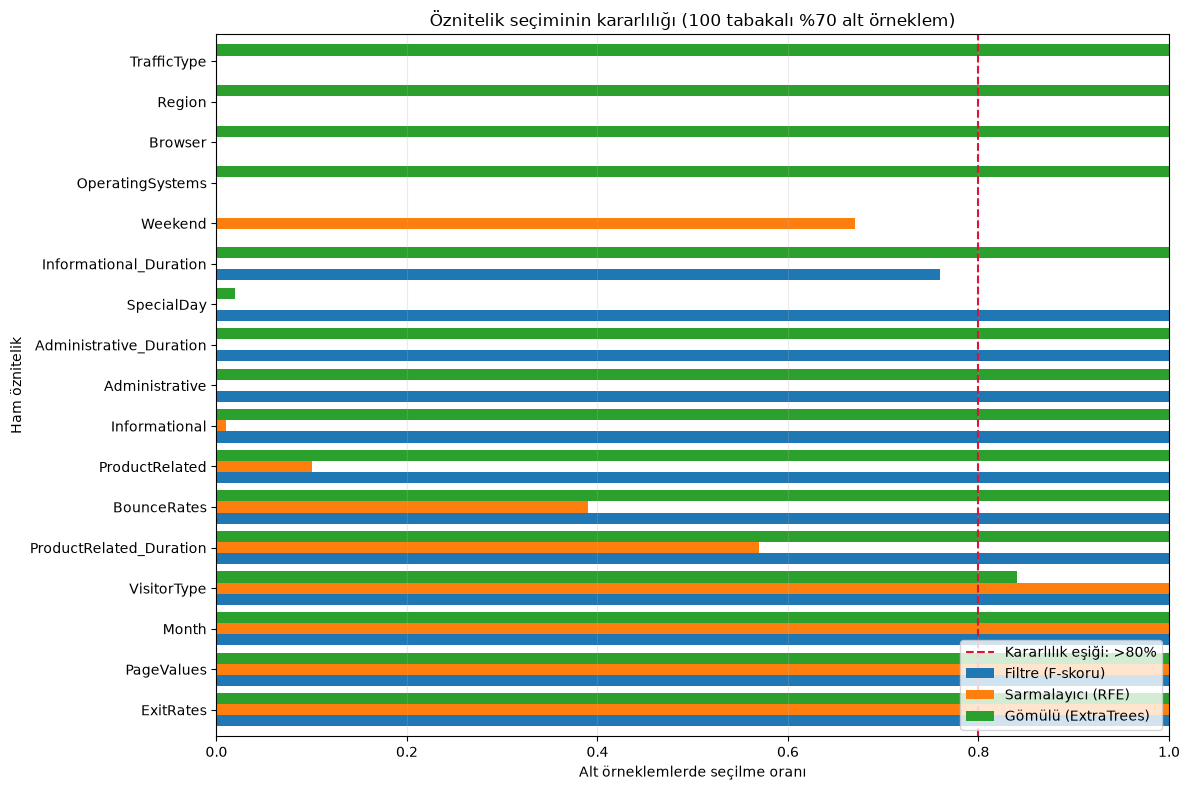

In [5]:
ax = stability.plot.barh(figsize=(12, 8), width=0.82)
ax.axvline(0.80, color="crimson", linestyle="--", linewidth=1.5, label="Kararlılık eşiği: >80%")
ax.set_xlim(0, 1)
ax.set_xlabel("Alt örneklemlerde seçilme oranı")
ax.set_ylabel("Ham öznitelik")
ax.set_title("Öznitelik seçiminin kararlılığı (100 tabakalı %70 alt örneklem)")
ax.legend(loc="lower right")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()


## 4. PageValues hariç duyarlılık analizi

`PageValues` tüm seçicilerde çok yüksek sıklıkta seçilmişti; ancak tahmin anında kullanılabilirliği belirsiz. Bu bölüm, aynı çapraz doğrulama bölmelerinde dört hattı `PageValues` olmadan tekrar karşılaştırır ve 100 tabakalı %70 alt örneklemde öznitelik seçimini yeniden ölçer. Amaç, önceki kararlılık ve başarım sonuçlarının bu sütuna ne kadar bağlı olduğunu görmektir. Bu karşılaştırma sızıntı olduğunu tek başına kanıtlamaz; sütunun tanımı ve tahmin zamanı ayrıca doğrulanmalıdır.

PageValues çıkarıldığında (aynı 5-katlı, 3-tekrarlı bölmeler):


,AveragePrecision ortalama ± std,ROCAUC ortalama ± std,BalancedAccuracy ortalama ± std,MacroF1 ortalama ± std
Hat,,,,
Seçimsiz,0.377 ± 0.023,0.780 ± 0.013,0.584 ± 0.009,0.601 ± 0.012
Filtre (F-skoru),0.348 ± 0.015,0.762 ± 0.009,0.588 ± 0.012,0.602 ± 0.015
Sarmalayıcı (RFE),0.328 ± 0.015,0.749 ± 0.008,0.598 ± 0.010,0.606 ± 0.009
Gömülü (ExtraTrees),0.356 ± 0.020,0.766 ± 0.013,0.571 ± 0.009,0.585 ± 0.011


PageValues hariç, seçimsiz hatta karşı kat-eşleşmeli AP farkı:


,Δ AP ort ± std,Medyan Δ AP,Δ AP %10–%90,Katlarda daha iyi
Hat,,,,
Filtre (F-skoru),-0.028 ± 0.013,-0.025,-0.045 – -0.014,0%
Sarmalayıcı (RFE),-0.049 ± 0.020,-0.052,-0.071 – -0.020,0%
Gömülü (ExtraTrees),-0.021 ± 0.014,-0.020,-0.034 – -0.003,0%


PageValues hariç 100 alt örneklemde ham öznitelik seçilme sıklığı:


,Filtre (F-skoru),Sarmalayıcı (RFE),Gömülü (ExtraTrees)
Administrative,100%,4%,100%
Administrative_Duration,100%,0%,100%
Informational,100%,2%,100%
Informational_Duration,100%,0%,100%
ProductRelated,100%,42%,100%
ProductRelated_Duration,100%,100%,100%
BounceRates,100%,70%,100%
ExitRates,100%,100%,100%
SpecialDay,100%,61%,68%
Month,100%,100%,100%


Filtre (F-skoru): PageValues dahil/hariç ortak kararlı sütunlar=['Administrative', 'Administrative_Duration', 'BounceRates', 'ExitRates', 'Informational', 'Month', 'ProductRelated', 'ProductRelated_Duration', 'SpecialDay', 'VisitorType']; yalnız dahil=[]; yalnız hariç=['Informational_Duration']
Sarmalayıcı (RFE): PageValues dahil/hariç ortak kararlı sütunlar=['ExitRates', 'Month', 'VisitorType']; yalnız dahil=[]; yalnız hariç=['ProductRelated_Duration']
Gömülü (ExtraTrees): PageValues dahil/hariç ortak kararlı sütunlar=['Administrative', 'Administrative_Duration', 'BounceRates', 'Browser', 'ExitRates', 'Informational', 'Informational_Duration', 'Month', 'OperatingSystems', 'ProductRelated', 'ProductRelated_Duration', 'Region', 'TrafficType']; yalnız dahil=['VisitorType']; yalnız hariç=[]


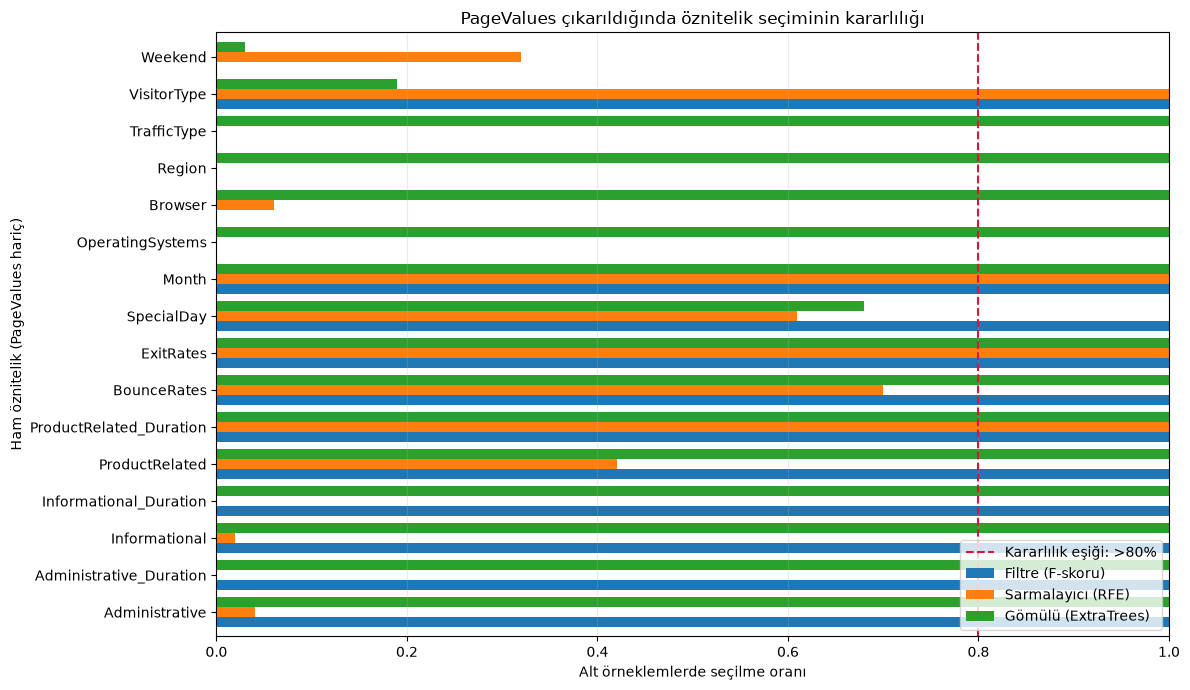

In [6]:
X_no_pagevalues = X.drop(columns=["PageValues"])
preprocessor_no_pagevalues = make_preprocessor(X_no_pagevalues)

pipelines_no_pagevalues = {"Seçimsiz": make_pipeline(data=X_no_pagevalues)}
pipelines_no_pagevalues.update({
    name: make_pipeline(selector, data=X_no_pagevalues)
    for name, selector in selectors.items()
})

no_pagevalues_scores = {}
no_pagevalues_rows = []
for name, pipe in pipelines_no_pagevalues.items():
    scores = cross_validate(
        pipe, X_no_pagevalues, y,
        cv=cv,
        scoring=scoring,
        n_jobs=1,
        return_train_score=False,
        error_score="raise",
    )
    no_pagevalues_scores[name] = scores
    row = {"Hat": name}
    for metric in scoring:
        values = scores[f"test_{metric}"]
        row[f"{metric} ortalama ± std"] = f"{values.mean():.3f} ± {values.std(ddof=1):.3f}"
        row[f"_{metric}_mean"] = values.mean()
    no_pagevalues_rows.append(row)

no_pagevalues_results = pd.DataFrame(no_pagevalues_rows).set_index("Hat")
print("PageValues çıkarıldığında (aynı 5-katlı, 3-tekrarlı bölmeler):")
display(no_pagevalues_results[[f"{m} ortalama ± std" for m in scoring]])

baseline_no_pv = no_pagevalues_scores["Seçimsiz"]["test_AveragePrecision"]
no_pv_delta_rows = []
for name in selectors:
    delta = no_pagevalues_scores[name]["test_AveragePrecision"] - baseline_no_pv
    no_pv_delta_rows.append({
        "Hat": name,
        "Δ AP ort ± std": f"{delta.mean():+.3f} ± {delta.std(ddof=1):.3f}",
        "Medyan Δ AP": f"{np.median(delta):+.3f}",
        "Δ AP %10–%90": f"{np.quantile(delta,.10):+.3f} – {np.quantile(delta,.90):+.3f}",
        "Katlarda daha iyi": f"{np.mean(delta > 0):.0%}",
    })
print("PageValues hariç, seçimsiz hatta karşı kat-eşleşmeli AP farkı:")
display(pd.DataFrame(no_pv_delta_rows).set_index("Hat"))

# Aynı 100 alt örneklemde seçicileri yeniden uydur; ham sütun düzeyinde frekansları hesapla.
selection_counts_no_pv = pd.DataFrame(
    0, index=X_no_pagevalues.columns, columns=list(selectors), dtype=int
)
for method_name, selector in selectors.items():
    for train_idx, _ in subsample_splits:
        X_sub = X_no_pagevalues.iloc[train_idx]
        y_sub = y[train_idx]
        selection_pipe = Pipeline([
            ("preprocess", clone(preprocessor_no_pagevalues)),
            ("select", clone(selector)),
        ])
        selection_pipe.fit(X_sub, y_sub)
        fitted_preprocessor = selection_pipe.named_steps["preprocess"]
        fitted_selector = selection_pipe.named_steps["select"]
        encoded_names = fitted_preprocessor.get_feature_names_out()
        chosen_names = encoded_names[fitted_selector.get_support()]
        chosen_raw = {encoded_to_raw(name, X_no_pagevalues.columns) for name in chosen_names}
        for raw_feature in X_no_pagevalues.columns:
            selection_counts_no_pv.loc[raw_feature, method_name] += int(raw_feature in chosen_raw)

stability_no_pagevalues = selection_counts_no_pv / len(subsample_splits)
print("PageValues hariç 100 alt örneklemde ham öznitelik seçilme sıklığı:")
display(stability_no_pagevalues.apply(lambda col: col.map(lambda value: f"{value:.0%}")))
for method_name in selectors:
    stable_without = set(stability_no_pagevalues.index[stability_no_pagevalues[method_name] > 0.80])
    stable_with = set(stability.index[stability[method_name] > 0.80]) - {"PageValues"}
    print(f"{method_name}: PageValues dahil/hariç ortak kararlı sütunlar={sorted(stable_with & stable_without)}; "
          f"yalnız dahil={sorted(stable_with - stable_without)}; yalnız hariç={sorted(stable_without - stable_with)}")

ax = stability_no_pagevalues.plot.barh(figsize=(12, 7), width=0.82)
ax.axvline(0.80, color="crimson", linestyle="--", linewidth=1.5, label="Kararlılık eşiği: >80%")
ax.set_xlim(0, 1)
ax.set_xlabel("Alt örneklemlerde seçilme oranı")
ax.set_ylabel("Ham öznitelik (PageValues hariç)")
ax.set_title("PageValues çıkarıldığında öznitelik seçiminin kararlılığı")
ax.legend(loc="lower right")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()


## 4. Yorum

**Kararlılık:** 100 tabakalı %70 alt örneklemde `ExitRates`, `PageValues`, `Month` ve `VisitorType` üç seçicide de %100 seçildi. Filtre yöntemi ayrıca `ProductRelated_Duration`, `BounceRates`, `ProductRelated`, `Informational`, `Administrative`, `Administrative_Duration` ve `SpecialDay` sütunlarını %100; RFE ise bu ortak dörtlü dışında hiçbir ham sütunu >%80 seçmedi. Gömülü ExtraTrees yöntemi 15/17 ham sütunu >%80 seçti; yalnız `Weekend` (%0) ve `SpecialDay` (%2) eşiğin altında kaldı. `ProductRelated_Duration` ve `BounceRates`, filtre ve gömülü yöntemde de %100 kararlıydı. `ExitRates`, `PageValues`, `Month` ve `VisitorType` bu yöntemler arasında en tutarlı sütunlardır. Sayfa gezinmesi ve oturum çıkış ölçümleri, ziyaretçi türü ve ay bağlamıyla birlikte öne çıkıyor; bu, ilişkinin nedensel olduğu anlamına gelmez.

**Modele katkı:** Seçimsiz geçici Random Forest'ın Average Precision değeri 0.748 ± 0.014'tü. Filtre 0.740 ± 0.015 (fark −0.008), RFE 0.705 ± 0.017 (−0.043), ExtraTrees tabanlı seçim 0.741 ± 0.015 (−0.007) verdi. Filtre ve gömülü yöntem farkları fold std büyüklüğüne yakındır; RFE düşüşü daha büyüktür. RFE'nin balanced accuracy'si 0.806'dan 0.813'e çıkarken AP ve macro-F1 düştü (0.812'den 0.795'e). Dolayısıyla seçim hiçbir ölçütte her zaman kazanç sağlamadı. Bu özet ortalama ± std verir; eşleştirilmiş kat farkı testi yapılmadığından istatistiksel anlamlılık iddia etmiyoruz.

**Kararlılık nasıl okunmalı:** Filtre ve gömülü seçici çok sayıda sütunu yüksek sıklıkta seçti; bu, seyrek bir özellik kümesi buldukları anlamına gelmez. Bir sütun, herhangi bir one-hot seviyesi seçildiğinde ham sütun olarak sayılır; kategori seviyelerinin hangisinin seçildiği bu tabloda görünmez. Farklı yöntemlerde ve alt örneklemlerde tekrar eden seçim, yalnızca bu veri, ön işleme ve model kurulumundaki örnekleme kararlılığıdır.

**PageValues sınırlaması:** `PageValues` tüm seçicilerde %100 seçilmiştir ve bu veri kümesinde satın alma hedefiyle çok güçlü ilişkilidir. Bu kararlılık, sütunun satın alma tahmin anında erişilebilir olduğunu veya hedef sızıntısı/proxy riski taşımadığını kanıtlamaz. P2 duyarlılık analizinde PageValues eklenince skorların belirgin yükselmesi de bu dikkat notunu destekler; zamanlama ve tanım doğrulanana kadar PageValues içeren sonuçlar ana operasyonel başarım gibi sunulmamalıdır.

**Kapsam:** Proje 1'in nihai modeli ve öğretim üyesi geri bildirimi paylaşılmadığı için çapraz doğrulama geçici class-weighted Random Forest ile yapıldı. Gerçek Proje 1 modelini `BASE_ESTIMATOR` yerine koyup tüm hücreleri yeniden çalıştırın; bu tablolar nihai P1 modeline aitmiş gibi aktarılmamalıdır.


## 5. Yorum ve savunma

### Öznitelik seçimi ve kararlılığı

`PageValues` dahil 100 tabakalı %70 alt örneklemde `ExitRates`, `PageValues`, `Month` ve `VisitorType` üç seçicide de >%80 sıklıkla seçildi (ilk üçü %100, VisitorType gömülü yöntemde %84). `PageValues` çıkarıldığında üç yöntemin ortak kararlı kümesi `ExitRates`, `Month` ve `ProductRelated_Duration` oldu. RFE'de `PageValues` yerine `ProductRelated_Duration` kararlı hale geldi; ExtraTrees'te VisitorType kararlılığı %84'ten %19'a düştü. Bu değişim, özellik seçim sıklığının veri kapsamına bağlı olduğunu gösterir.

### Seçimin modele katkısı

| Kurulum | Seçimsiz | Filtre | RFE | ExtraTrees |
|---|---:|---:|---:|---:|
| PageValues dahil AP (ortalama ± std) | 0.748 ± 0.014 | 0.740 ± 0.015 | 0.705 ± 0.017 | 0.741 ± 0.015 |
| PageValues hariç AP (ortalama ± std) | 0.377 ± 0.023 | 0.348 ± 0.015 | 0.328 ± 0.015 | 0.356 ± 0.020 |

Aynı 15 CV katındaki eşleşik AP farkı PageValues dahilken filtre için −0.008 ± 0.005, RFE için −0.043 ± 0.015 ve ExtraTrees için −0.007 ± 0.003'tür. PageValues hariçken farklar sırasıyla −0.028 ± 0.013, −0.049 ± 0.020 ve −0.021 ± 0.014'tür. Seçiciler iki kurulumda da 15 katın hiçbirinde seçimsiz hattı geçmedi. RFE PageValues hariç balanced accuracy ve macro-F1'i hafif artırsa da AP'si düştü; metrik seçimi yorumu değiştirebilir. Tekrarlı CV katları bağımsız olmadığından bunlar tanımlayıcı paired özetlerdir, anlamlılık testi değildir.

### PageValues yorumu

Aynı bölmelerde PageValues dahil ve hariç seçimsiz AP sırasıyla 0.748 ve 0.377'dir; seçim yöntemlerinde dahil/hariç farkı +0.371 ile +0.392 arasındadır. Bu, model puanının PageValues'a çok duyarlı olduğunu gösterir; tek başına hedef sızıntısı kanıtı değildir. PageValues'ın satın alma tahmin anında gerçekten mevcut olup olmadığı veri tanımı ve zamanlama bilgisiyle doğrulanmalıdır. Bu doğrulama olmadan PageValues içeren skorlar operasyonel başarım gibi sunulmamalıdır.

### Yöntem sınırı ve sonraki adım

Filtre ve gömülü yöntem birçok sütunu >%80 seçti; kararlılık, seçimin seyrek olduğu anlamına gelmez. Ham sütun, bir one-hot seviyesinden en az biri seçildiğinde seçilmiş sayılır; kategori seviyelerindeki değişkenlik görünmez. Ayrıca Proje 1'in nihai modeli ve öğretim üyesi geri bildirimi verilmediği için analiz geçici class-weighted Random Forest ile yapıldı. Gerçek P1 modeli `BASE_ESTIMATOR` içine konup tüm notebook baştan çalıştırılmalıdır.
